# Level 1 – Task 2: Exploratory Data Analysis (EDA)
**Dataset:** Iris Dataset (cleaned)  
**Tools:** Python, pandas, matplotlib, seaborn

## 1. Load the Cleaned Dataset

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('iris_cleaned.csv')
print('Shape:', df.shape)
df.head()

Shape: (148, 5)


,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


## 2. Summary Statistics

In [2]:
print('=== Mean ===')
print(df.describe().loc['mean'].round(2))

print('\n=== Median ===')
print(df.median(numeric_only=True).round(2))

print('\n=== Mode ===')
print(df.mode().iloc[0])

print('\n=== Standard Deviation ===')
print(df.describe().loc['std'].round(2))

=== Mean ===
sepal_length    5.83
sepal_width     3.05
petal_length    3.79
petal_width     1.20
Name: mean, dtype: float64

=== Median ===
sepal_length    5.70
sepal_width     3.00
petal_length    4.28
petal_width     1.30
dtype: float64

=== Mode ===
sepal_length           5.7
sepal_width            3.0
petal_length           1.4
petal_width            0.2
species         versicolor
Name: 0, dtype: object

=== Standard Deviation ===
sepal_length    0.81
sepal_width     0.44
petal_length    1.73
petal_width     0.75
Name: std, dtype: float64


## 3. Data Distributions – Histograms

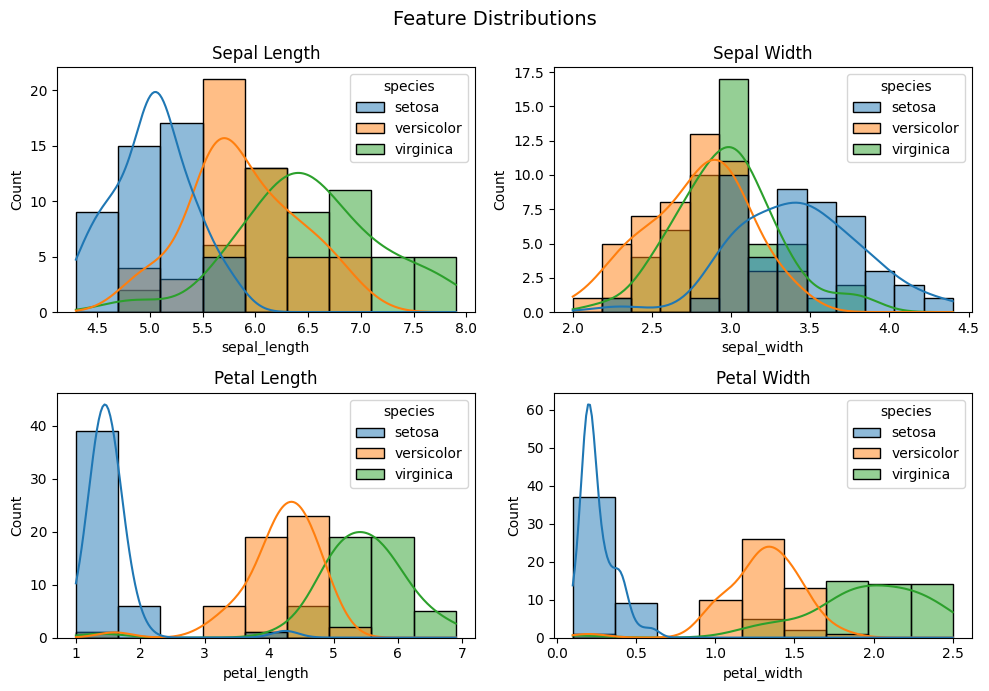

In [3]:
num_cols = ['sepal_length', 'sepal_width', 'petal_length', 'petal_width']

fig, axes = plt.subplots(2, 2, figsize=(10, 7))
fig.suptitle('Feature Distributions', fontsize=14)

for ax, col in zip(axes.flatten(), num_cols):
    sns.histplot(data=df, x=col, hue='species', kde=True, ax=ax)
    ax.set_title(col.replace('_', ' ').title())

plt.tight_layout()
plt.savefig('plots/histograms.png', dpi=150)
plt.show()

## 4. Boxplots – Spread and Outliers

C:\Users\YSS\AppData\Local\Temp\ipykernel_18044\3105495088.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='species', y=col, ax=ax, palette='Set2')
C:\Users\YSS\AppData\Local\Temp\ipykernel_18044\3105495088.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='species', y=col, ax=ax, palette='Set2')
C:\Users\YSS\AppData\Local\Temp\ipykernel_18044\3105495088.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='species', y=col, ax=ax, palette='Set2')
C:\Users\YSS\AppData\Local\Temp\ipykernel_18044\3105495088

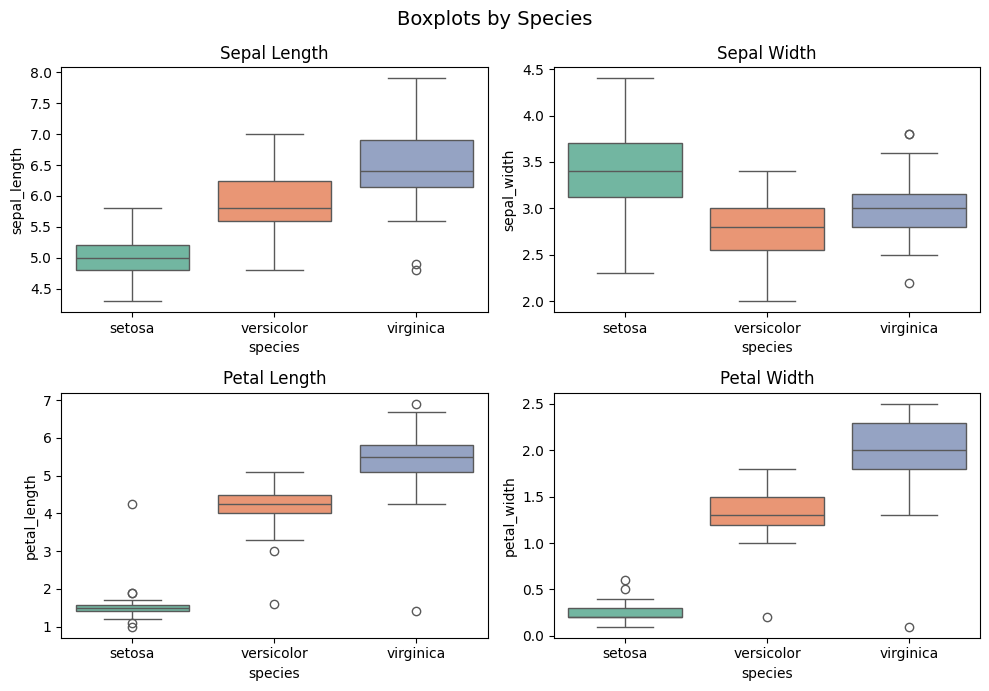

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(10, 7))
fig.suptitle('Boxplots by Species', fontsize=14)

for ax, col in zip(axes.flatten(), num_cols):
    sns.boxplot(data=df, x='species', y=col, ax=ax, palette='Set2')
    ax.set_title(col.replace('_', ' ').title())

plt.tight_layout()
plt.savefig('plots/boxplots.png', dpi=150)
plt.show()

## 5. Scatter Plots – Feature Relationships

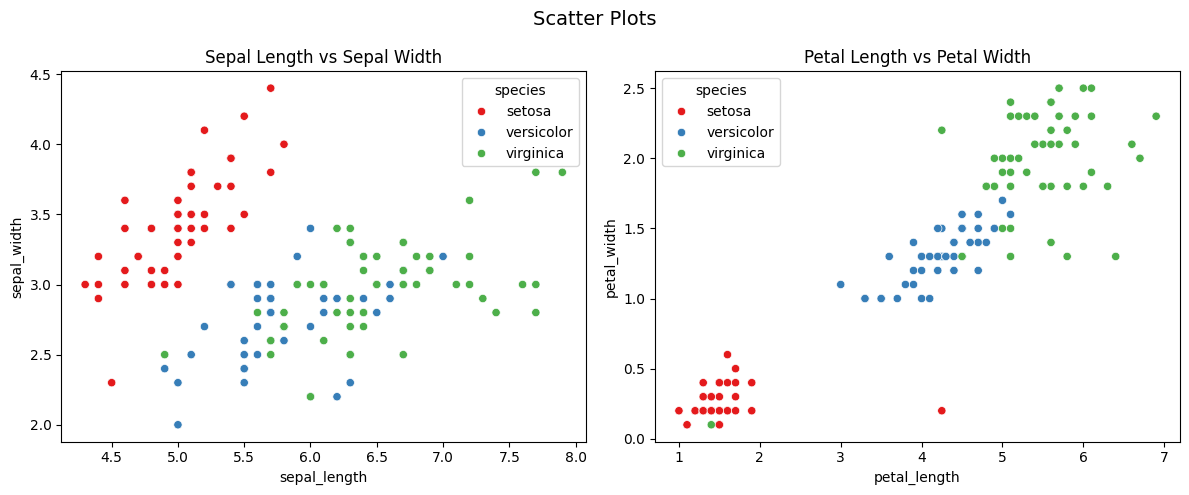

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
fig.suptitle('Scatter Plots', fontsize=14)

sns.scatterplot(data=df, x='sepal_length', y='sepal_width', hue='species', ax=axes[0], palette='Set1')
axes[0].set_title('Sepal Length vs Sepal Width')

sns.scatterplot(data=df, x='petal_length', y='petal_width', hue='species', ax=axes[1], palette='Set1')
axes[1].set_title('Petal Length vs Petal Width')

plt.tight_layout()
plt.savefig('plots/scatter_plots.png', dpi=150)
plt.show()

## 6. Correlation Heatmap

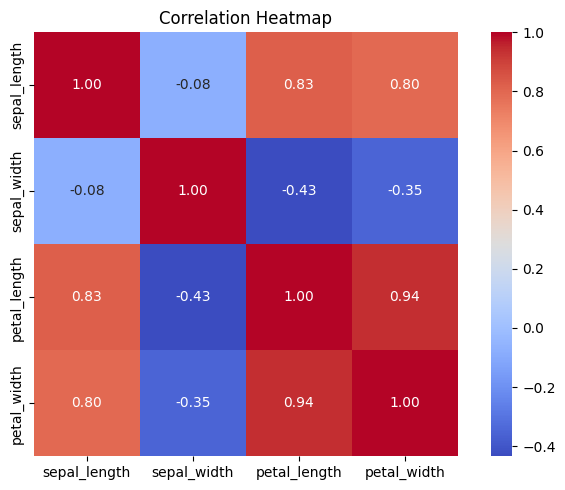


Strongest correlation:
petal_length  petal_width     0.939389
petal_width   petal_length    0.939389
sepal_length  petal_length    0.826256
dtype: float64


In [6]:
plt.figure(figsize=(7, 5))
corr = df[num_cols].corr()
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', square=True)
plt.title('Correlation Heatmap')
plt.tight_layout()
plt.savefig('plots/correlation_heatmap.png', dpi=150)
plt.show()

print('\nStrongest correlation:')
corr_unstacked = corr.abs().unstack().sort_values(ascending=False)
print(corr_unstacked[corr_unstacked < 1].head(3))

## 7. Pairplot – Full Feature Overview

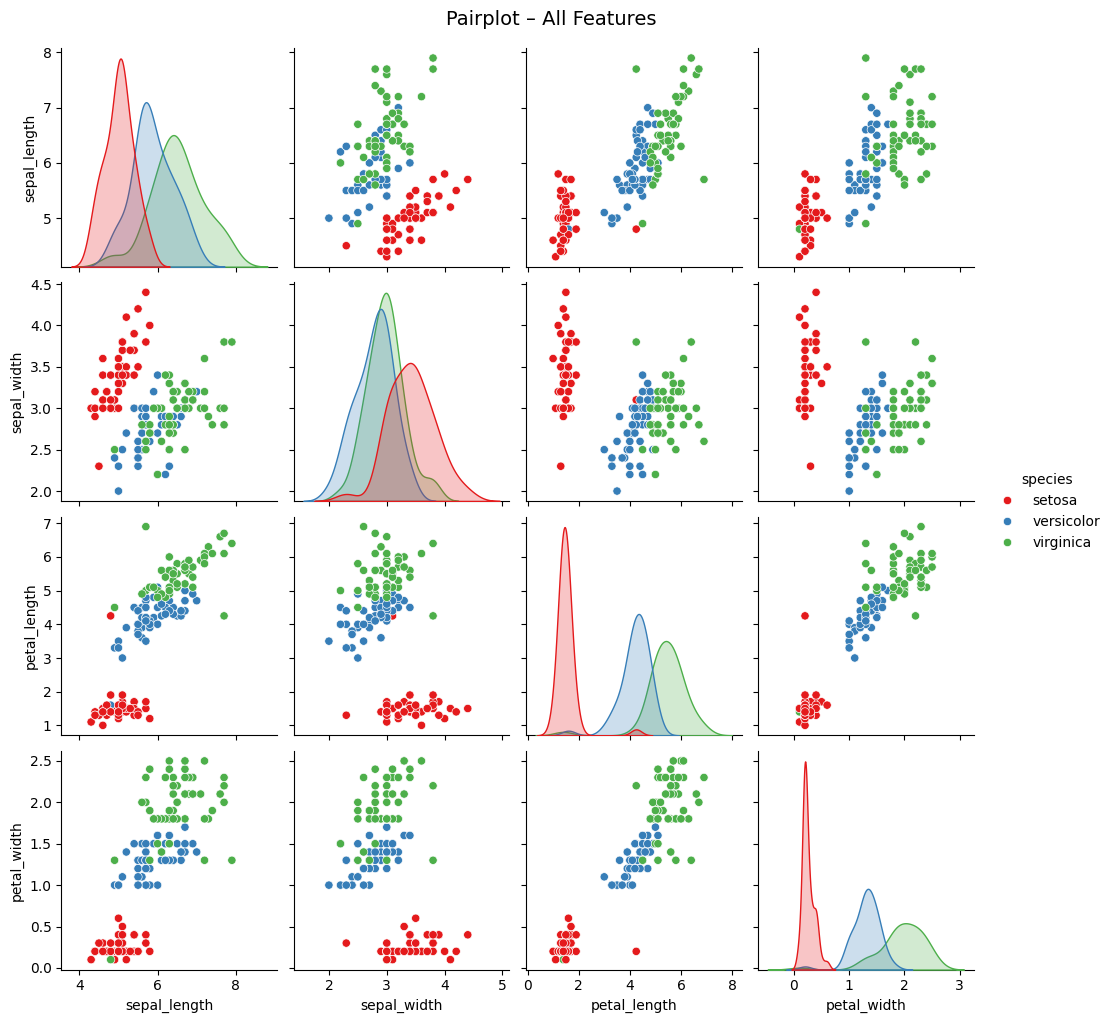

In [7]:
pair = sns.pairplot(df, hue='species', palette='Set1', diag_kind='kde')
pair.fig.suptitle('Pairplot – All Features', y=1.02, fontsize=14)
plt.savefig('plots/pairplot.png', dpi=150)
plt.show()

## Summary of Key Findings

- **Petal length and petal width** are highly correlated (r ≈ 0.96), making them the most discriminative features.
- **Setosa** is clearly separable from the other two species across all features.
- **Versicolor and Virginica** overlap slightly, especially in sepal measurements.
- Sepal width shows the least variation across species.